In [1]:
print("Hello! Python is working.")


Hello! Python is working.


In [5]:
from pathlib import Path

print("python running from:")
print(Path.cwd())   #curr working dir

python running from:
C:\Users\fmali


In [ ]:
current_folder = Path.cwd()

print("Current folder:", current_folder)
print("\nItems inside this folder:\n")

for item in sorted(current_folder.iterdir()): #list items
    if item.is_dir(): 
        print("[FOLDER]", item.name)
    else:
        print("[FILE]  ", item.name)

In [ ]:
SCUT_ROOT = Path(r"C:\Users\f") #-> path to scrut

for folder in sorted(SCUT_ROOT.rglob("*")): #rglob for all the files and folders
    if folder.is_dir():
        print(folder.relative_to(SCUT_ROOT))
#roi -> region of interest

full
full\dev
full\dev\real
full\dev\real\21
full\dev\real\22
full\dev\real\23
full\dev\real\24
full\dev\real\25
full\dev\real\26
full\dev\real\27
full\dev\real\28
full\dev\real\29
full\dev\real\30
full\dev\real\31
full\dev\real\32
full\dev\real\33
full\dev\real\34
full\dev\real\35
full\dev\real\36
full\dev\real\37
full\dev\real\38
full\dev\real\39
full\dev\real\40
full\dev\spoof
full\dev\spoof\21
full\dev\spoof\22
full\dev\spoof\23
full\dev\spoof\24
full\dev\spoof\25
full\dev\spoof\26
full\dev\spoof\27
full\dev\spoof\28
full\dev\spoof\29
full\dev\spoof\30
full\dev\spoof\31
full\dev\spoof\32
full\dev\spoof\33
full\dev\spoof\34
full\dev\spoof\35
full\dev\spoof\36
full\dev\spoof\37
full\dev\spoof\38
full\dev\spoof\39
full\dev\spoof\40
full\test
full\test\real
full\test\real\100
full\test\real\101
full\test\real\41
full\test\real\42
full\test\real\43
full\test\real\44
full\test\real\45
full\test\real\46
full\test\real\47
full\test\real\48
full\test\real\49
full\test\real\50
full\test\real

In [ ]:
import pandas as pd

SCUT_ROOT = Path(r"C:\Users\f") #-> path to scrut

image_extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

rows = []

for representation in ["full", "roi"]:
    for split in ["train", "dev", "test"]:
        for label in ["real", "spoof"]:
            folder = SCUT_ROOT / representation / split / label

            if not folder.exists():
                print("Missing folder:", folder)
                continue

            images = [
                file for file in folder.rglob("*")
                if file.is_file()
                and file.suffix.lower() in image_extensions
            ]

            rows.append({
                "Representation": representation,
                "Split": split,
                "Class": label,
                "Image count": len(images)
            })

counts = pd.DataFrame(rows)

display(counts)

# real -> images from actual fingers
# spoof -> images from PAI/ fake fingers

,Representation,Split,Class,Image count
0,full,train,real,720
1,full,train,spoof,720
2,full,dev,real,720
3,full,dev,spoof,720
4,full,test,real,2160
5,full,test,spoof,2160
6,roi,train,real,720
7,roi,train,spoof,716
8,roi,dev,real,720
9,roi,dev,spoof,720


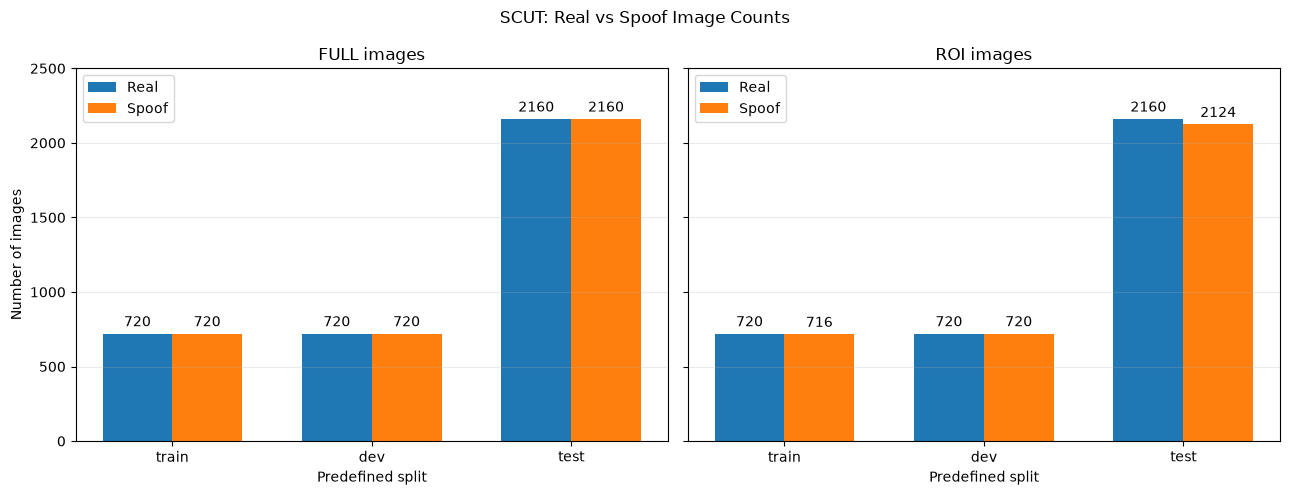

In [12]:
%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np

splits = ["train", "dev", "test"]
representations = ["full", "roi"]

x = np.arange(len(splits))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

for ax, representation in zip(axes, representations):

    # Get the counts for this representation from the previous cell
    subset = counts[counts["Representation"] == representation]

    # Retrieve the real and spoof counts for each split
    real = [
        subset[(subset["Split"] == split) &
               (subset["Class"] == "real")]["Image count"].sum()
        for split in splits
    ]

    spoof = [
        subset[(subset["Split"] == split) &
               (subset["Class"] == "spoof")]["Image count"].sum()
        for split in splits
    ]

    # Draw the bars
    bars_real = ax.bar(x - width / 2, real, width, label="Real")
    bars_spoof = ax.bar(x + width / 2, spoof, width, label="Spoof")

    # Display counts above each bar
    ax.bar_label(bars_real, padding=3)
    ax.bar_label(bars_spoof, padding=3)

    ax.set_title(f"{representation.upper()} images")
    ax.set_xticks(x)
    ax.set_xticklabels(splits)
    ax.set_xlabel("Predefined split")
    ax.set_ylim(0, 2500)
    ax.grid(axis="y", alpha=0.25)
    ax.legend()

axes[0].set_ylabel("Number of images")
fig.suptitle("SCUT: Real vs Spoof Image Counts")
plt.tight_layout()
plt.show()

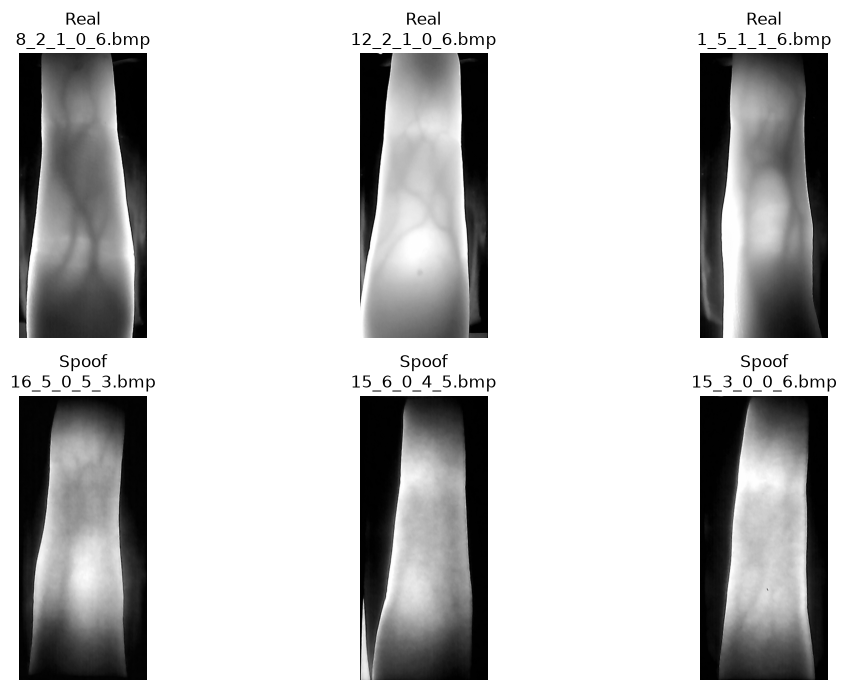

In [14]:
# show images from train and full

from PIL import Image
import random

# Choose the representation and split to inspect
representation = "full"
split = "train"

base_path = Path(SCUT_ROOT) / representation / split

# Find one image from each class
real_images = list((base_path / "real").rglob("*"))
spoof_images = list((base_path / "spoof").rglob("*"))

# Keep image files only
real_images = [p for p in real_images if p.suffix.lower() in [".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"]]
spoof_images = [p for p in spoof_images if p.suffix.lower() in [".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"]]

# Select up to 3 images from each class
random.seed(42)
real_samples = random.sample(real_images, min(3, len(real_images)))
spoof_samples = random.sample(spoof_images, min(3, len(spoof_images)))

# Display the images
samples = [("Real", p) for p in real_samples] + [("Spoof", p) for p in spoof_samples]

fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for ax, (label, image_path) in zip(axes.flat, samples):
    with Image.open(image_path) as img:
        ax.imshow(img, cmap="gray")
    ax.set_title(f"{label}\n{image_path.name}")
    ax.axis("off")

for ax in axes.flat[len(samples):]:
    ax.axis("off")

plt.tight_layout()
plt.show()